# Diabetic Retinopathy using VGG16 & VGG19   

# Diabetic Retinopathy using VGG16 & VGG19   

## 1. Import Library

In [1]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import pickle
import numpy as np
import matplotlib.pyplot as plt
# 1. IMPORT KIẾN TRÚC VÀ HÀM TIỀN XỬ LÝ CỦA HỌ VGG
from tensorflow.keras.applications import VGG16, VGG19
# Mặc dù VGG16 và VGG19 tiền xử lý giống nhau, thực hành tốt nhất là import đúng chuẩn
from tensorflow.keras.applications.vgg16 import preprocess_input as preprocess_vgg16
from tensorflow.keras.applications.vgg19 import preprocess_input as preprocess_vgg19

I0000 00:00:1784903074.286544    1475 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1784903076.396432    1475 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1784903108.892805    1475 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Xóa rác bộ nhớ GPU
tf.keras.backend.clear_session()

## 2. Load Data

In [3]:
BATCH_SIZE=4

In [4]:
with open("../../../data/processed/aptos/full_aptos/full_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [5]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing 

In [6]:
X = data['data']
y = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 2344 | Số lớp: 5 | Kích thước ảnh: 300x300


In [7]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [8]:
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

In [9]:
def preprocess_function_vgg16(image, label): 
    image = tf.cast(image, tf.float32)
    image = preprocess_vgg16(image)
    return image, label
def preprocess_function_vgg19(image, label): 
    image = tf.cast(image, tf.float32)
    image = preprocess_vgg19(image)
    return image, label

### Data train vgg16 

In [10]:
# 3. KHỞI TẠO TẬP DATASET TRAIN
with tf.device('/CPU:0'):
    train_dataset_vgg16 = tf.data.Dataset.from_tensor_slices((x_train, y_train))
    # Áp dụng hàm tiền xử lý (map) và cho phép CPU tự động tối ưu luồng (AUTOTUNE)
    train_dataset_vgg16 = train_dataset_vgg16.map(preprocess_function_vgg16, num_parallel_calls=tf.data.AUTOTUNE)
    # Chia lô (batch) và nạp sẵn dữ liệu cho vòng lặp kế tiếp (prefetch) để tăng tốc GPU
    train_dataset_vgg16 = train_dataset_vgg16.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    test_dataset_vgg16 = tf.data.Dataset.from_tensor_slices((x_test, y_test))
    test_dataset_vgg16 = test_dataset_vgg16.map(preprocess_function_vgg16, num_parallel_calls=tf.data.AUTOTUNE)
    test_dataset_vgg16 = test_dataset_vgg16.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    val_dataset_vgg16 = tf.data.Dataset.from_tensor_slices((x_val, y_val))
    val_dataset_vgg16 = val_dataset_vgg16.map(preprocess_function_vgg16, num_parallel_calls=tf.data.AUTOTUNE)
    val_dataset_vgg16 = val_dataset_vgg16.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1784903145.351627    1475 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


### Data train vgg19

In [11]:
# 3. KHỞI TẠO TẬP DATASET TRAIN
with tf.device('/CPU:0'):
    train_dataset_vgg19 = tf.data.Dataset.from_tensor_slices((x_train, y_train))
    # Áp dụng hàm tiền xử lý (map) và cho phép CPU tự động tối ưu luồng (AUTOTUNE)
    train_dataset_vgg19 = train_dataset_vgg19.map(preprocess_function_vgg19, num_parallel_calls=tf.data.AUTOTUNE)
    # Chia lô (batch) và nạp sẵn dữ liệu cho vòng lặp kế tiếp (prefetch) để tăng tốc GPU
    train_dataset_vgg19 = train_dataset_vgg19.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    test_dataset_vgg19 = tf.data.Dataset.from_tensor_slices((x_test, y_test))
    test_dataset_vgg19 = test_dataset_vgg19.map(preprocess_function_vgg19, num_parallel_calls=tf.data.AUTOTUNE)
    test_dataset_vgg19 = test_dataset_vgg19.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    val_dataset_vgg19 = tf.data.Dataset.from_tensor_slices((x_val, y_val))
    val_dataset_vgg19 = val_dataset_vgg19.map(preprocess_function_vgg19, num_parallel_calls=tf.data.AUTOTUNE)
    val_dataset_vgg19 = val_dataset_vgg19.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

### Ảnh tệp train

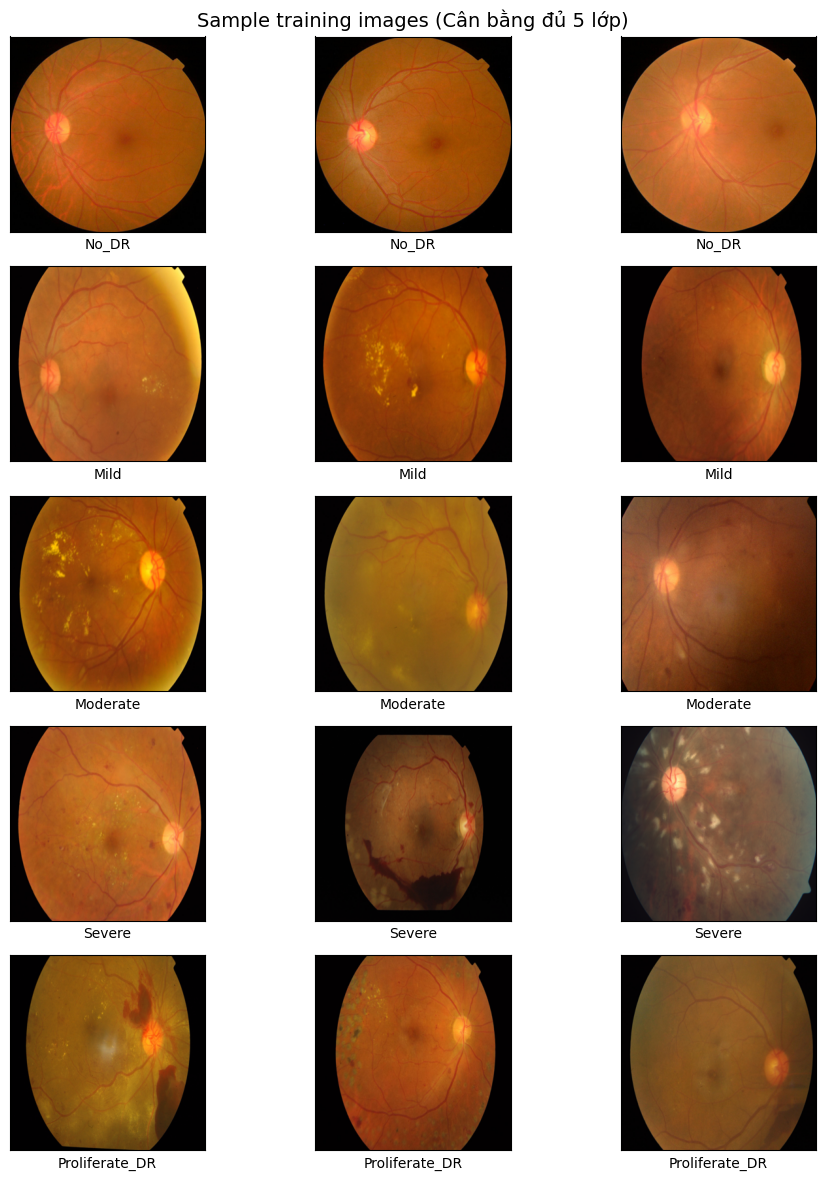

In [12]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_train[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample training images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

### Ảnh tệp test

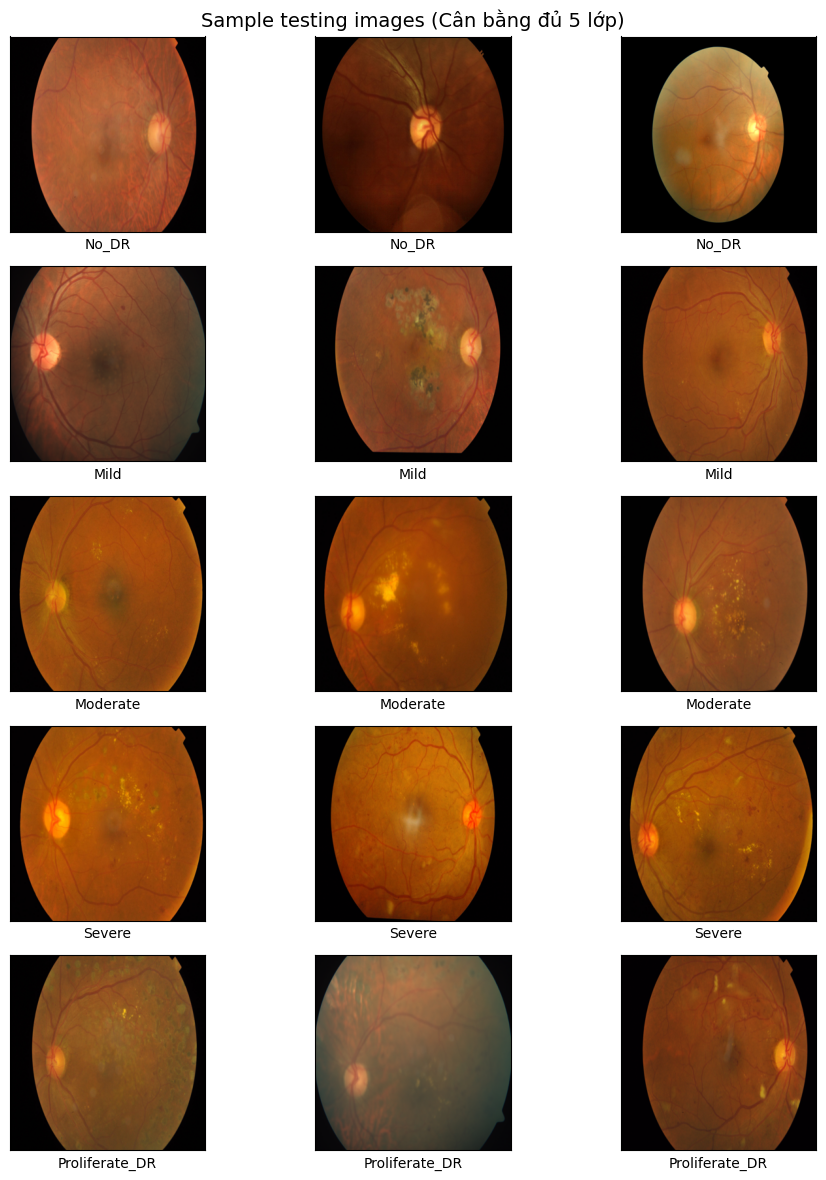

In [13]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_test[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample testing images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng các model VGG

In [14]:
def build_vgg_model(base_model_class, input_shape, num_classes, model_name):
    # Khởi tạo Base Model (VGG16 hoặc VGG19)
    base_model = base_model_class(weights='imagenet', 
                                  include_top=False, 
                                  input_shape=input_shape)
    
    # Đóng băng (Freeze) phần thân để Transfer Learning
    base_model.trainable = False
    
    # Xây dựng Classification Head (Rất cần BatchNormalization cho VGG)
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    
    # Chuẩn hóa ngay sau khi gộp đặc trưng
    x = BatchNormalization()(x)
    
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x) 
    x = BatchNormalization()(x)
    
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions, name=model_name)
    
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

### 4.1 Xây dựng model VGG16 

In [15]:
model_vgg16 = build_vgg_model(VGG16, (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, "VGG16_APTOS")
model_vgg16.summary()

Model: "VGG16_APTOS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 300, 300, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 300, 300, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 150, 150, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 150, 150, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 150, 150, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 75, 75, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 75, 75, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 75, 75, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 75, 75, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 37, 37, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 37, 37, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 18, 18, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,04

 Total params: 15,114,053 (57.66 MB)

 Trainable params: 397,317 (1.52 MB)

 Non-trainable params: 14,716,736 (56.14 MB)

### 4.2 Xây dựng model VGG19

In [16]:
model_vgg19 = build_vgg_model(VGG19, (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, "VGG19_APTOS")
model_vgg19.summary()

Model: "VGG19_APTOS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 300, 300, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 300, 300, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 150, 150, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 150, 150, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 150, 150, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 75, 75, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 75, 75, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 75, 75, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 75, 75, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 75, 75, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 37, 37, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 37, 37, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 18, 18, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │             

 Total params: 20,423,749 (77.91 MB)

 Trainable params: 397,317 (1.52 MB)

 Non-trainable params: 20,026,432 (76.39 MB)

## 5. Compile & Train 

### 5.1 Compile & train VGG16

In [17]:
model_vgg16.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/vgg16_aptos_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_vgg16 = model_vgg16.fit(
    train_dataset_vgg16,
    epochs=100, 
    validation_data=val_dataset_vgg16,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784903158.377940    4734 service.cc:153] XLA service 0x7c7b20038160 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1784903158.378038    4734 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1784903158.552272    4734 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1784903159.190965    4734 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1784903159.303816    4734 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3975__.83
W0000 00:00:1784903159.770884    4836 hlo_rematerialization.cc:3204] Can't reduce memory use below 3.02GiB (3243912033 bytes) by rematerialization; only reduced to 4.20GiB (4510162976 bytes), down from 4.20GiB (4510162976 bytes) originally
W0000 00:00:1784903170.726704    4734 bfc_all


Epoch 1: val_accuracy improved from None to 0.76109, saving model to ../../../data/models/vgg16_aptos_best.keras

Epoch 1: finished saving model to ../../../data/models/vgg16_aptos_best.keras
586/586 - 272s - 465ms/step - accuracy: 0.6229 - loss: 1.1198 - val_accuracy: 0.7611 - val_loss: 0.7190 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.76109 to 0.77133, saving model to ../../../data/models/vgg16_aptos_best.keras

Epoch 2: finished saving model to ../../../data/models/vgg16_aptos_best.keras
586/586 - 61s - 103ms/step - accuracy: 0.6647 - loss: 0.9317 - val_accuracy: 0.7713 - val_loss: 0.7001 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy improved from 0.77133 to 0.77474, saving model to ../../../data/models/vgg16_aptos_best.keras

Epoch 3: finished saving model to ../../../data/models/vgg16_aptos_best.keras
586/586 - 57s - 97ms/step - accuracy: 0.6779 - loss: 0.8688 - val_accuracy: 0.7747 - val_loss: 0.7011 - learning_rate: 0.0010
Epoch 4/10

### 5.2 Compile & train VGG19 

In [18]:
model_vgg19.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/vgg19_aptos_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_vgg19 = model_vgg19.fit(
    train_dataset_vgg19,
    epochs=100, 
    validation_data=val_dataset_vgg19,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784904504.405511    4737 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_65307__.86



Epoch 1: val_accuracy improved from None to 0.75939, saving model to ../../../data/models/vgg19_aptos_best.keras

Epoch 1: finished saving model to ../../../data/models/vgg19_aptos_best.keras
586/586 - 79s - 134ms/step - accuracy: 0.5922 - loss: 1.1958 - val_accuracy: 0.7594 - val_loss: 0.7690 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.75939 to 0.77474, saving model to ../../../data/models/vgg19_aptos_best.keras

Epoch 2: finished saving model to ../../../data/models/vgg19_aptos_best.keras
586/586 - 67s - 114ms/step - accuracy: 0.6544 - loss: 0.9694 - val_accuracy: 0.7747 - val_loss: 0.6945 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy improved from 0.77474 to 0.79010, saving model to ../../../data/models/vgg19_aptos_best.keras

Epoch 3: finished saving model to ../../../data/models/vgg19_aptos_best.keras
586/586 - 66s - 113ms/step - accuracy: 0.6689 - loss: 0.8815 - val_accuracy: 0.7901 - val_loss: 0.6633 - learning_rate: 0.0010
Epoch 4/10

## 6. Visualize Training

### 6.1 Visualize Training VGG16

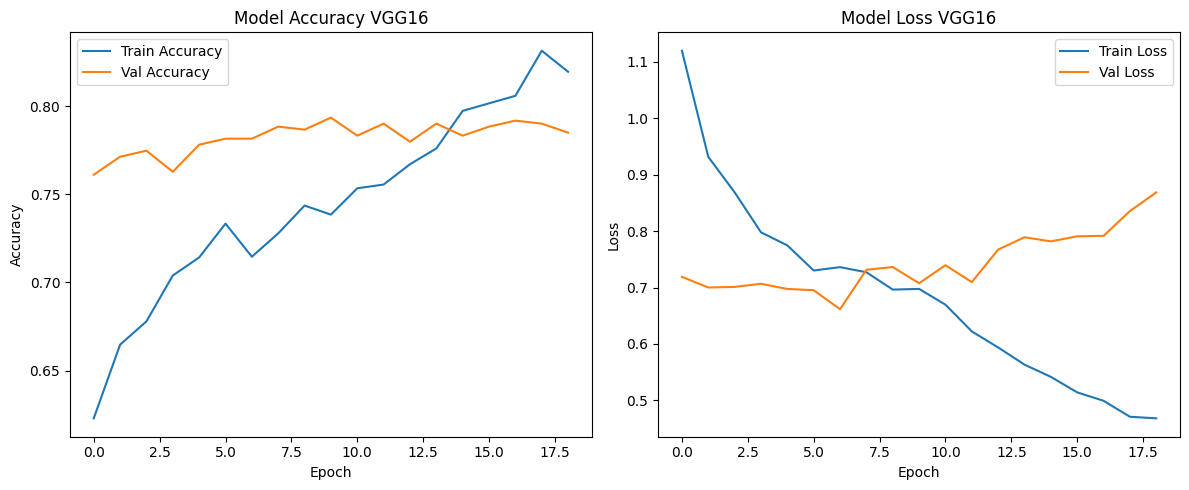

In [19]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_vgg16.history['accuracy'], label='Train Accuracy')
plt.plot(history_vgg16.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy VGG16')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_vgg16.history['loss'],     label='Train Loss')
plt.plot(history_vgg16.history['val_loss'], label='Val Loss')
plt.title('Model Loss VGG16')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.2 Visualize Training VGG19 

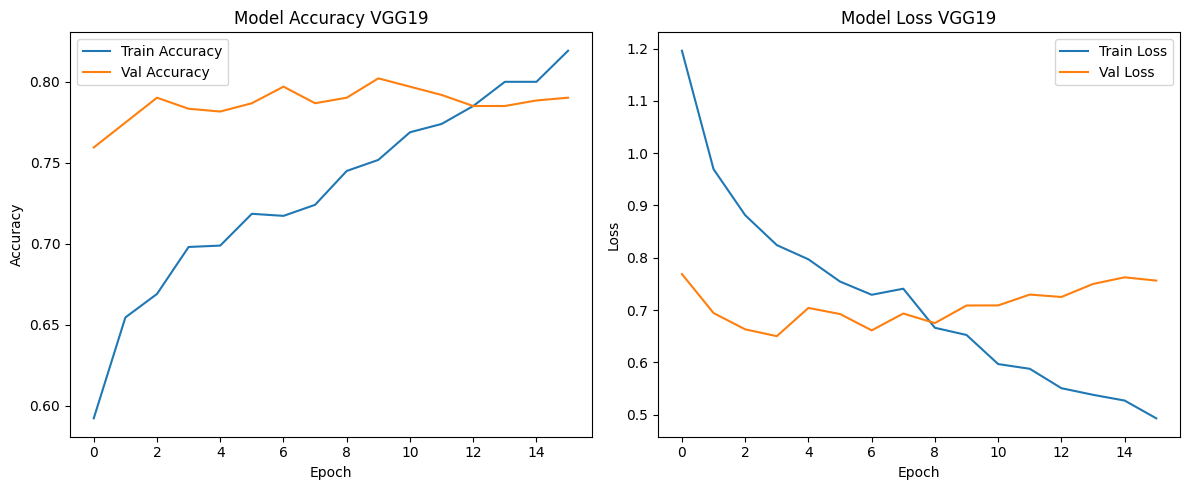

In [20]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_vgg19.history['accuracy'], label='Train Accuracy')
plt.plot(history_vgg19.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy VGG19')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_vgg19.history['loss'],     label='Train Loss')
plt.plot(history_vgg19.history['val_loss'], label='Val Loss')
plt.title('Model Loss VGG19')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7.Evualte on test set

In [21]:
test_loss_vgg16, test_acc_vgg16 = model_vgg16.evaluate(test_dataset_vgg16, verbose=0)
print(f'Test Loss: {test_loss_vgg16:.4f}')
print(f'Test Accuracy: {test_acc_vgg16:.4f}') 

Test Loss: 0.6199
Test Accuracy: 0.8115


In [22]:
test_loss_vgg19, test_acc_vgg19 = model_vgg19.evaluate(test_dataset_vgg19, verbose=0)
print(f'Test Loss: {test_loss_vgg19:.4f}')
print(f'Test Accuracy: {test_acc_vgg19:.4f}') 

Test Loss: 0.6471
Test Accuracy: 0.7923
